# Week7_ex1 — Transient stability of a generator on an infinite bus (light check)

Reproduces Examples 12.3–12.8 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.) and checks Example 12.6 against PowerWorld's transient stability run (Example12_6). pandapower has no time-domain solver, so it supplies the power flow and the network admittances, the swing equation is integrated with SciPy, and Example 12.8's reduced admittance matrices are checked against the textbook because the case does not display them.

![PowerWorld one-line](Images/Week7_ex1_result_image.png)

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import case5
from case4 import (S_BASE, GEN, build_case, solve, internal_emf, transfer_admittance, critical_angle,
                   swing, fixed_step, max_angle_equal_area, critical_clearing_time, is_stable,
                   modified_euler, residual_band, compare)

PW6 = "PowerWorld Example12_6"
PW8 = "PowerWorld Example12_8"
TXT = "Textbook"
IMG = Path("Images")
IMG.mkdir(exist_ok=True)

# 1. Generator voltage setpoint from the PowerWorld Buses table (bus 4). The textbook gets the same
#    1.0946 pu from 1.0 pu delivered at 0.95 lagging through X = 0.10 + 0.20 || (0.10 + 0.20) = 0.22
V_SET = 1.09464
LINES_OUT = ((1, 3), (2, 3))     # the breakers that clear the bus 3 fault in Example 12.6


def pre_fault():
    return build_case(V_SET)


def pf_measure(n):
    rb = n.res_bus
    vals = {f"V{k} [pu]": rb.vm_pu[k] for k in (1, 3)}
    vals.update({f"delta{k} [deg]": rb.va_degree[k] for k in (1, 3, 4)})
    vals.update({"Gen Q [Mvar]": n.res_gen.q_mvar.iloc[0],
                 "Infinite bus P [MW]": n.res_ext_grid.p_mw.iloc[0],
                 "Infinite bus Q [Mvar]": n.res_ext_grid.q_mvar.iloc[0]})
    return pd.Series(vals)


# 2. Pre-fault power flow (Example 12.3) against the PowerWorld Buses table; PowerWorld lists the
#    infinite bus as a generator, so its absorbed power appears with a negative sign
net = solve(pre_fault())
got = pf_measure(net)
band = residual_band(pre_fault, pf_measure)
ref = {"V1 [pu]": 1.04634, "V3 [pu]": 1.02940, "delta1 [deg]": 6.59, "delta3 [deg]": 4.46,
       "delta4 [deg]": 11.59, "Gen Q [Mvar]": 57.24, "Infinite bus P [MW]": -100.00,
       "Infinite bus Q [Mvar]": -32.86}
digits = {"pu": 5e-6, "deg": 5e-3, "MW": 5e-3, "Mvar": 5e-3}
compare([(q, got[q], r, digits[q.split("[")[1][:-1]] + band[q], PW6) for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,V1 [pu],1.04634,1.04634,0.00000,0.00011,True,PowerWorld Example12_6
1,V3 [pu],1.02941,1.02940,0.00001,0.00015,True,PowerWorld Example12_6
2,delta1 [deg],6.58547,6.59000,0.00453,0.02356,True,PowerWorld Example12_6
3,delta3 [deg],4.45722,4.46000,0.00278,0.02102,True,PowerWorld Example12_6
4,delta4 [deg],11.59423,11.59000,0.00423,0.02910,True,PowerWorld Example12_6
5,Gen Q [Mvar],57.24197,57.24000,0.00197,0.13251,True,PowerWorld Example12_6
6,Infinite bus P [MW],-100.00000,-100.00000,0.00000,0.30500,True,PowerWorld Example12_6
7,Infinite bus Q [Mvar],-32.86564,-32.86000,0.00564,0.16167,True,PowerWorld Example12_6


In [2]:
# 3. Internal EMF behind X'd and the current the generator delivers (Example 12.3). V_SET carries
#    PowerWorld's five printed decimals, so the residual band also covers that rounding
def emf_measure(n):
    e, _, i = internal_emf(n)
    return pd.Series({"|I| [pu]": abs(i), "angle I [deg]": np.degrees(np.angle(i)),
                      "|E'| [pu]": abs(e), "delta0 [deg]": np.degrees(np.angle(e))})


e_int, v_t, i_t = internal_emf(net)
DELTA0 = float(np.angle(e_int))
got = emf_measure(net)
band = residual_band(pre_fault, emf_measure)
rows = [(q, got[q], r, d + band[q], TXT) for q, r, d in (("|I| [pu]", 1.05263, 5e-6), ("angle I [deg]", -18.195, 5e-4),
                                                         ("|E'| [pu]", 1.2812, 5e-5), ("delta0 [deg]", 23.946, 5e-4))]
# GENCLS reports E' as Efd, and OriginalAngle is the rotor angle at t = 0
rows += [("|E'| (Efd) [pu]", got["|E'| [pu]"], 1.2812, 5e-5 + band["|E'| [pu]"], PW6 + " Results from RAM"),
         ("delta0 (OriginalAngle) [deg]", got["delta0 [deg]"], 23.946, 5e-4 + band["delta0 [deg]"], PW6 + " Results from RAM")]
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,|I| [pu],1.05262,1.05263,0.00001,0.00058,True,Textbook
1,angle I [deg],-18.19344,-18.19500,0.00156,0.05121,True,Textbook
2,|E'| [pu],1.28118,1.28120,0.00002,0.00039,True,Textbook
3,delta0 [deg],23.94612,23.94600,0.00012,0.02405,True,Textbook
4,|E'| (Efd) [pu],1.28118,1.28120,0.00002,0.00039,True,PowerWorld Example12_6 Results from RAM
5,delta0 (OriginalAngle) [deg],23.94612,23.94600,0.00012,0.02405,True,PowerWorld Example12_6 Results from RAM


In [3]:
# 4. Peak electrical power of the three networks: pandapower's Ybus plus the internal EMF node,
#    Kron-reduced to the two sources. Fault-on = bus 3 shorted (deleted), post-fault = lines 1-3, 2-3 out
E = abs(e_int)
P_PRE = E * abs(transfer_admittance(net))
P_FAULT_BUS3 = E * abs(transfer_admittance(net, faulted_bus=3))
P_POST = E * abs(transfer_admittance(solve(build_case(V_SET, LINES_OUT))))


# 5. Input-rounding band: the textbook evaluates each Pmax from rounded intermediates
#    (E' = 1.2812, V_th = 0.3333, X_th = 0.46666), so the same formula on exact intermediates shows
#    how far the printed value can sit from the exact one
def textbook_pmax(e, vth, xth):
    return {"pre": e / 0.52, "fault": e * vth / xth, "post": e / 0.60}


printed = textbook_pmax(1.2812, 0.3333, 0.46666)
exact = textbook_pmax(E, 1 / 3, 0.4 + 0.2 * 0.1 / 0.3)
rows = []
for key, got_p, ref_p in (("pre-fault", P_PRE, 2.4638), ("fault-on", P_FAULT_BUS3, 0.9152), ("post-fault", P_POST, 2.1353)):
    rows.append((f"Pmax {key} [pu]", got_p, ref_p, 5e-5 + abs(printed[key.split("-")[0]] - exact[key.split("-")[0]]), "Examples 12.3, 12.6"))
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,Pmax pre-fault [pu],2.46380,2.4638,0.00000,0.00010,True,"Examples 12.3, 12.6"
1,Pmax fault-on [pu],0.91513,0.9152,0.00007,0.00011,True,"Examples 12.3, 12.6"
2,Pmax post-fault [pu],2.13529,2.1353,0.00001,0.00009,True,"Examples 12.3, 12.6"


In [4]:
# 6. Equal-area results of Examples 12.4-12.6. pandapower's Pmax values go into the swing equation
#    (SciPy, tight tolerances); the band repeats the textbook's own algebra on its printed inputs
#    (delta0 = 0.4179 rad, Pmax rounded to four decimals) and on the exact ones
TXT_IN = {"d0": 0.4179, "pre": 2.4638, "fault": 0.9152, "post": 2.1353}
EX_IN = {"d0": DELTA0, "pre": P_PRE, "fault": P_FAULT_BUS3, "post": P_POST}


def ex124(p):
    # fault at the generator terminal (Pe = 0) for 3 cycles, then the pre-fault network again
    d1 = p["d0"] + math.pi * 60 / (2 * 3.0) * 0.05 ** 2
    return d1, max_angle_equal_area(1.0, p["pre"], d1, d1 - p["d0"])


def ex125(p):
    dcr, _ = critical_angle(1.0, 0.0, p["pre"], p["d0"])
    return dcr, math.sqrt(4 * 3.0 * (dcr - p["d0"]) / (2 * math.pi * 60))


def ex126(p):
    return critical_angle(1.0, p["fault"], p["post"], p["d0"])[0]


t, d = swing(0.05, DELTA0, 1.0, 0.0, P_PRE, t_end=1.0)
ours = {"12.4 delta(0.05 s) [rad]": np.interp(0.05, t, d),
        "12.4 delta max [rad]": d.max(),
        "12.5 delta_cr [rad]": ex125(EX_IN)[0],
        "12.5 t_cr [s]": critical_clearing_time(DELTA0, 1.0, 0.0, P_PRE),
        "12.6 delta_cr [rad]": ex126(EX_IN)}
f_txt, f_ex = (dict(zip(ours, [*ex124(p), *ex125(p), ex126(p)])) for p in (TXT_IN, EX_IN))
# Example 12.6 prints 1.9812 rad = 113.57 deg, but 1.9812 rad is 113.51 deg; the radian value is compared
ref = {"12.4 delta(0.05 s) [rad]": 0.4964, "12.4 delta max [rad]": 0.7003, "12.5 delta_cr [rad]": 1.5489,
       "12.5 t_cr [s]": 0.1897, "12.6 delta_cr [rad]": 1.9812}
compare([(q, ours[q], r, 5e-5 + abs(f_txt[q] - f_ex[q]), "Example " + q.split()[0]) for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,12.4 delta(0.05 s) [rad],0.49648,0.4964,0.00008,0.00009,True,Example 12.4
1,12.4 delta max [rad],0.70025,0.7003,0.00005,0.00006,True,Example 12.4
2,12.5 delta_cr [rad],1.54888,1.5489,0.00002,0.00007,True,Example 12.5
3,12.5 t_cr [s],0.18973,0.1897,0.00003,0.00005,True,Example 12.5
4,12.6 delta_cr [rad],1.98113,1.9812,0.00007,0.00012,True,Example 12.6


In [5]:
# 7. Example 12.7: the textbook's modified Euler program with its own constants (dt = 0.01 s) reproduces
#    Table 12.1; case 1 clears at 1.95 rad (stable), case 2 at 2.09 rad (unstable)
case1 = modified_euler(0.34, 0.9152, 2.1353, 0.4179)
case2 = modified_euler(0.36, 0.9152, 2.1353, 0.4179)
table = {("Case 1", 0.34): (1.954, 383.658), ("Case 1", 0.86): (0.516, 362.750),
         ("Case 2", 0.36): (2.090, 383.876), ("Case 2", 0.86): (9.257, 404.934)}
rows = []
for (case, t_s), (d_ref, w_ref) in table.items():
    run = case1 if case == "Case 1" else case2
    rows += [(f"{case} delta({t_s} s) [rad]", run.loc[t_s, "delta [rad]"], d_ref, 5e-4, "Table 12.1"),
             (f"{case} omega({t_s} s) [rad/s]", run.loc[t_s, "omega [rad/s]"], w_ref, 5e-4, "Table 12.1")]
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,Case 1 delta(0.34 s) [rad],1.95422,1.954,0.00022,0.0005,True,Table 12.1
1,Case 1 omega(0.34 s) [rad/s],383.65772,383.658,0.00028,0.0005,True,Table 12.1
2,Case 1 delta(0.86 s) [rad],0.51645,0.516,0.00045,0.0005,True,Table 12.1
3,Case 1 omega(0.86 s) [rad/s],362.75032,362.750,0.00032,0.0005,True,Table 12.1
4,Case 2 delta(0.36 s) [rad],2.08957,2.090,0.00043,0.0005,True,Table 12.1
5,Case 2 omega(0.36 s) [rad/s],383.87631,383.876,0.00031,0.0005,True,Table 12.1
6,Case 2 delta(0.86 s) [rad],9.25675,9.257,0.00025,0.0005,True,Table 12.1
7,Case 2 omega(0.86 s) [rad/s],404.93366,404.934,0.00034,0.0005,True,Table 12.1


In [6]:
# 8. Example 12.6 in PowerWorld: fault at bus 3 at t = 0, lines 1-3 and 2-3 opened at the clearing time,
#    GENCLS (H = 3, D = 0, X'd = 0.30), 0.5-cycle time step, 5 s run. The clearing time was moved by hand
T_CR = critical_clearing_time(DELTA0, 1.0, P_FAULT_BUS3, P_POST)
outcomes = {0.34: "stable", 0.345: "loses synchronism"}
rows = []
for tc, pw in outcomes.items():
    ok = is_stable(tc, DELTA0, 1.0, P_FAULT_BUS3, P_POST, t_end=5.0)
    rows.append({"Clearing time [s]": tc, PW6: pw, "Swing equation": "stable" if ok else "loses synchronism"})
assert all(r[PW6] == r["Swing equation"] for r in rows)
rows.append({"Clearing time [s]": round(T_CR, 4), PW6: "between 0.34 and 0.345",
             "Swing equation": "critical clearing time"})
pd.DataFrame(rows)

,Clearing time [s],PowerWorld Example12_6,Swing equation
0,0.3400,stable,stable
1,0.3450,loses synchronism,loses synchronism
2,0.3428,between 0.34 and 0.345,critical clearing time


In [7]:
# 9. Extremes of the stable 0.34 s run against PowerWorld's Minimum/Maximum Values table.
#    Without damping the exact swing repeats with the same peak; an explicit second-order step of
#    0.5 cycle adds a little energy every swing, so the peaks creep up. The integration band is how far
#    such a step moves each value over 5 s (trapezoidal and midpoint variants, worst of the two)
TC = 0.34
t, d = swing(TC, DELTA0, 1.0, P_FAULT_BUS3, P_POST, t_end=5.0)
w = 1 + np.gradient(d, t) / (2 * math.pi * 60)
exact_ext = pd.Series({"Max angle [deg]": np.degrees(d.max()), "Min angle [deg]": np.degrees(d.min()),
                       "Max speed [pu]": w.max(), "Min speed [pu]": w.min()})
fixed = {m: fixed_step(m, TC, DELTA0, 1.0, P_FAULT_BUS3, P_POST) for m in ("heun", "midpoint")}


def extremes(df):
    return pd.Series({"Max angle [deg]": np.degrees(df["delta [rad]"].max()),
                      "Min angle [deg]": np.degrees(df["delta [rad]"].min()),
                      "Max speed [pu]": df["w [pu]"].max(), "Min speed [pu]": df["w [pu]"].min()})


band = pd.concat([(extremes(f) - exact_ext).abs() for f in fixed.values()], axis=1).max(axis=1)
ref = {"Max angle [deg]": 144.704, "Min angle [deg]": -43.610, "Max speed [pu]": 1.037, "Min speed [pu]": 0.963}
digits = {"deg": 5e-4, "pu": 5e-4}
compare([(q, exact_ext[q], r, digits[q.split("[")[1][:-1]] + band[q], PW6 + " Results from RAM")
         for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,Max angle [deg],143.29789,144.704,1.40611,1.67783,True,PowerWorld Example12_6 Results from RAM
1,Min angle [deg],-43.51423,-43.610,0.09577,0.15950,True,PowerWorld Example12_6 Results from RAM
2,Max speed [pu],1.03744,1.037,0.00044,0.00057,True,PowerWorld Example12_6 Results from RAM
3,Min speed [pu],0.96256,0.963,0.00044,0.00056,True,PowerWorld Example12_6 Results from RAM


In [8]:
# 10. Where the peaks come from: PowerWorld's largest swing is the last one (4.475 s), the same pattern
#     the fixed-step runs show, while the accurate solution peaks at the same angle every cycle
rows = []
for name, df in (("Swing equation, tight tolerance", pd.DataFrame({"t [s]": t, "delta [rad]": d})),
                 ("Fixed 0.5-cycle step, trapezoidal", fixed["heun"]),
                 ("Fixed 0.5-cycle step, midpoint", fixed["midpoint"])):
    i_max, i_min = df["delta [rad]"].idxmax(), df["delta [rad]"].idxmin()
    rows.append({"Integration": name,
                 "First peak [deg]": np.degrees(df.loc[df["t [s]"] < 1.0, "delta [rad]"].max()),
                 "Largest peak [deg]": np.degrees(df.loc[i_max, "delta [rad]"]), "Peak at [s]": df.loc[i_max, "t [s]"],
                 "Lowest trough [deg]": np.degrees(df.loc[i_min, "delta [rad]"]), "Trough at [s]": df.loc[i_min, "t [s]"]})
rows.append({"Integration": PW6, "First peak [deg]": np.nan, "Largest peak [deg]": 144.704, "Peak at [s]": 4.475,
             "Lowest trough [deg]": -43.610, "Trough at [s]": 4.975})
pd.DataFrame(rows).round(3)

,Integration,First peak [deg],Largest peak [deg],Peak at [s],Lowest trough [deg],Trough at [s]
0,"Swing equation, tight tolerance",143.298,143.298,2.479,-43.514,4.891
1,"Fixed 0.5-cycle step, trapezoidal",143.593,144.975,4.498,-43.642,4.998
2,"Fixed 0.5-cycle step, midpoint",143.416,144.591,4.473,-43.673,4.965
3,PowerWorld Example12_6,NaN,144.704,4.475,-43.610,4.975


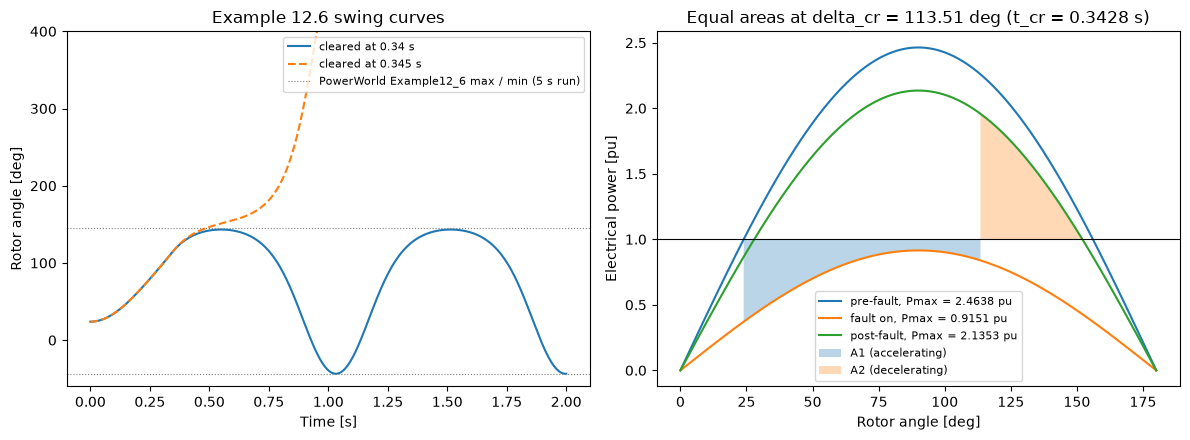

In [9]:
# 11. Swing curves on both sides of the critical clearing time, and the equal-area picture at T_CR
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for tc, style in ((0.34, "-"), (0.345, "--")):
    tt, dd = swing(tc, DELTA0, 1.0, P_FAULT_BUS3, P_POST, t_end=2.0)
    ax1.plot(tt, np.degrees(dd), style, label=f"cleared at {tc} s")
ax1.axhline(144.704, color="gray", lw=0.8, ls=":", label=f"{PW6} max / min (5 s run)")
ax1.axhline(-43.610, color="gray", lw=0.8, ls=":")
ax1.set_ylim(-60, 400)
ax1.set_xlabel("Time [s]")
ax1.set_ylabel("Rotor angle [deg]")
ax1.set_title("Example 12.6 swing curves")
ax1.legend(fontsize=8)

dg = np.linspace(0, math.pi, 400)
d_cr = critical_angle(1.0, P_FAULT_BUS3, P_POST, DELTA0)[0]
d_u = math.pi - math.asin(1.0 / P_POST)
for p, label in ((P_PRE, "pre-fault"), (P_FAULT_BUS3, "fault on"), (P_POST, "post-fault")):
    ax2.plot(np.degrees(dg), p * np.sin(dg), label=f"{label}, Pmax = {p:.4f} pu")
ax2.axhline(1.0, color="k", lw=0.8)
a1 = np.linspace(DELTA0, d_cr, 100)
a2 = np.linspace(d_cr, d_u, 100)
ax2.fill_between(np.degrees(a1), P_FAULT_BUS3 * np.sin(a1), 1.0, alpha=0.3, label="A1 (accelerating)")
ax2.fill_between(np.degrees(a2), 1.0, P_POST * np.sin(a2), alpha=0.3, label="A2 (decelerating)")
ax2.set_xlabel("Rotor angle [deg]")
ax2.set_ylabel("Electrical power [pu]")
ax2.set_title(f"Equal areas at delta_cr = {np.degrees(d_cr):.2f} deg (t_cr = {T_CR:.4f} s)")
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(IMG / "Week7_ex1_swing_curves_equal_area.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# 12. What a static N-1 study sees: the post-contingency power flow is the same whatever the clearing
#     time, and it converges with a comfortable angle, while the dynamic outcome flips near 0.343 s
post = solve(build_case(V_SET, LINES_OUT))
rows = []
for tc in (0.10, 0.20, 0.30, 0.34, 0.345, 0.40):
    rows.append({"Clearing time [s]": tc,
                 "Post-fault power flow": "converged" if post.converged else "failed",
                 "Post-fault equilibrium delta [deg]": np.degrees(math.asin(1.0 / P_POST)),
                 "Swing equation": "stable" if is_stable(tc, DELTA0, 1.0, P_FAULT_BUS3, P_POST) else "loses synchronism"})
pd.DataFrame(rows).round(3)

,Clearing time [s],Post-fault power flow,Post-fault equilibrium delta [deg],Swing equation
0,0.100,converged,27.925,stable
1,0.200,converged,27.925,stable
2,0.300,converged,27.925,stable
3,0.340,converged,27.925,stable
4,0.345,converged,27.925,loses synchronism
5,0.400,converged,27.925,loses synchronism


In [11]:
# 13. Example 12.8: PowerWorld stores the GENCLS data on each machine's own base (400 and 800 MVA).
#     Impedance scales by S_BASE / S_machine and H by S_machine / S_BASE before either enters Ybus
rows = []
for bus, g in case5.GENS.items():
    sys = case5.on_system_base(g)
    rows.append({"Generator bus": bus, "Gen MVA base": g["mva"], "X'd as entered [pu]": g["Xdp"],
                 "H as entered [s]": g["H"], "X'd on 100 MVA [pu]": sys["Xdp"], "H on 100 MVA [s]": sys["H"],
                 "1/X'd if left unconverted [pu]": 1 / g["Xdp"], "1/X'd converted [pu]": 1 / sys["Xdp"]})
assert [r["X'd on 100 MVA [pu]"] for r in rows] == [0.05, 0.025]   # the textbook's X'd1 and X'd2
pd.DataFrame(rows)

,Generator bus,Gen MVA base,X'd as entered [pu],H as entered [s],X'd on 100 MVA [pu],H on 100 MVA [s],1/X'd if left unconverted [pu],1/X'd converted [pu]
0,1,400.0,0.2,5.0,0.050,20.0,5.0,20.0
1,3,800.0,0.2,5.0,0.025,40.0,5.0,40.0


In [12]:
# 14. Pre-fault power flow of Example 12.8 (the Example 6.14 operating point) against PowerWorld
def pf8_measure(n):
    rb = n.res_bus
    vals = {f"V{k} [pu]": rb.vm_pu[k] for k in (2, 4, 5)}
    vals.update({f"delta{k} [deg]": rb.va_degree[k] for k in (2, 3, 4, 5)})
    vals.update({"Gen 1 P [MW]": n.res_ext_grid.p_mw.iloc[0], "Gen 1 Q [Mvar]": n.res_ext_grid.q_mvar.iloc[0],
                 "Gen 3 Q [Mvar]": n.res_gen.q_mvar.iloc[0], "Capacitor [Mvar]": -n.res_shunt.q_mvar.iloc[0]})
    return pd.Series(vals)


net8 = case5.solve(case5.build_case())
got = pf8_measure(net8)
band = residual_band(case5.build_case, pf8_measure, solver=case5.solve)
ref = {"V2 [pu]": 0.95911, "V4 [pu]": 1.03620, "V5 [pu]": 1.00452, "delta2 [deg]": -19.78,
       "delta3 [deg]": -0.42, "delta4 [deg]": -2.69, "delta5 [deg]": -4.43, "Gen 1 P [MW]": 385.37,
       "Gen 1 Q [Mvar]": -36.50, "Gen 3 Q [Mvar]": 160.46, "Capacitor [Mvar]": 183.98}
digits = {"pu": 5e-6, "deg": 5e-3, "MW": 5e-3, "Mvar": 5e-3}
compare([(q, got[q], r, digits[q.split("[")[1][:-1]] + band[q], PW8 + " Buses") for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,V2 [pu],0.95911,0.95911,0.00000,0.00014,True,PowerWorld Example12_8 Buses
1,V4 [pu],1.03620,1.03620,0.00000,0.00004,True,PowerWorld Example12_8 Buses
2,V5 [pu],1.00452,1.00452,0.00000,0.00006,True,PowerWorld Example12_8 Buses
3,delta2 [deg],-19.77943,-19.78000,0.00057,0.01540,True,PowerWorld Example12_8 Buses
4,delta3 [deg],-0.41538,-0.42000,0.00462,0.01322,True,PowerWorld Example12_8 Buses
5,delta4 [deg],-2.68549,-2.69000,0.00451,0.01267,True,PowerWorld Example12_8 Buses
6,delta5 [deg],-4.43183,-4.43000,0.00183,0.00975,True,PowerWorld Example12_8 Buses
7,Gen 1 P [MW],385.37458,385.37000,0.00458,0.41944,True,PowerWorld Example12_8 Buses
8,Gen 1 Q [Mvar],-36.49522,-36.50000,0.00478,0.25948,True,PowerWorld Example12_8 Buses
9,Gen 3 Q [Mvar],160.45562,160.46000,0.00438,0.32173,True,PowerWorld Example12_8 Buses


In [13]:
# 15. What equation (12.5.5) adds to the network Ybus: each load as conj(S)/|V|^2 at its pre-fault voltage
#     and 1/jX'd at each generator. The textbook folds the 184 Mvar capacitor into the bus 2 load and uses
#     V2 = 0.959, V3 = 1.05; the band is how far half a printed voltage digit moves the admittance
XDP = {bus: case5.on_system_base(g)["Xdp"] for bus, g in case5.GENS.items()}
Y11, Y12, Y22 = case5.stability_ybus(net8, XDP)
v2 = net8.res_bus.vm_pu[2]
s2 = complex(8.0, 2.8) + 1j * net8.res_shunt.q_mvar.iloc[0] / S_BASE      # load plus the capacitor's actual Mvar
s3 = complex(0.8, 0.4)
y_load2 = np.conj(s2) / v2 ** 2
y_load3 = np.conj(s3) / net8.res_bus.vm_pu[3] ** 2
v_band2 = abs(np.conj(s2) / (v2 - 5e-4) ** 2 - y_load2)
rows = [("Y load2 G [pu]", y_load2.real, 8.699, 5e-4 + v_band2, "Example 12.8"),
        ("Y load2 B [pu]", y_load2.imag, -1.044, 5e-4 + v_band2, "Example 12.8"),
        ("Y load3 G [pu]", y_load3.real, 0.7256, 5e-5, "Example 12.8"),
        ("Y load3 B [pu]", y_load3.imag, -0.3628, 5e-5, "Example 12.8"),
        ("Y22 (1,1) B [pu]", Y22[0, 0].imag, -20.0, 5e-2, "Example 12.8"),
        ("Y22 (2,2) B [pu]", Y22[1, 1].imag, -40.0, 5e-2, "Example 12.8"),
        ("Y12 (bus 1, gen 1) B [pu]", Y12[0, 0].imag, 20.0, 5e-2, "Example 12.8"),
        ("Y12 (bus 3, gen 2) B [pu]", Y12[2, 1].imag, 40.0, 5e-2, "Example 12.8")]
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,Y load2 G [pu],8.69675,8.6990,0.00225,0.00964,True,Example 12.8
1,Y load2 B [pu],-1.04386,-1.0440,0.00014,0.00964,True,Example 12.8
2,Y load3 G [pu],0.72562,0.7256,0.00002,0.00005,True,Example 12.8
3,Y load3 B [pu],-0.36281,-0.3628,0.00001,0.00005,True,Example 12.8
4,"Y22 (1,1) B [pu]",-20.00000,-20.0000,0.00000,0.05000,True,Example 12.8
5,"Y22 (2,2) B [pu]",-40.00000,-40.0000,0.00000,0.05000,True,Example 12.8
6,"Y12 (bus 1, gen 1) B [pu]",20.00000,20.0000,0.00000,0.05000,True,Example 12.8
7,"Y12 (bus 3, gen 2) B [pu]",40.00000,40.0000,0.00000,0.05000,True,Example 12.8


In [14]:
# 16. The full Y11 against the textbook. Y11 adds the load and generator terms to the textbook's 5 x 5
#     Ybus, whose terms are printed with as few as two decimals (7.46 for 7.458) and up to 1.6 units of
#     the last digit off the exact branch admittances (G15 = 3.728 vs 1/(0.0015 + j0.02) -> 3.72902), so
#     the tolerance is two units of that Ybus term plus the bus 2 voltage band. The textbook prints
#     Y11(4,5) = Y11(5,4) = -3.572 - j39.68; its own Ybus has +j39.68 (an inductive branch), so the sign
#     is corrected
ref = {(1, 1): (3.728, -69.72), (1, 5): (-3.728, 49.72), (2, 2): (11.38, -29.50), (2, 4): (-0.892, 9.92),
       (2, 5): (-1.784, 19.84), (3, 3): (8.186, -139.80), (3, 4): (-7.46, 99.44), (4, 4): (11.92, -148.0),
       (4, 5): (-3.572, 39.68), (5, 5): (9.084, -108.6)}


units = {(1, 1): (1e-3, 1e-2), (1, 5): (1e-3, 1e-2), (2, 2): (1e-2, 1e-2), (2, 4): (1e-3, 1e-2),
         (2, 5): (1e-3, 1e-2), (3, 3): (1e-2, 1e-2), (3, 4): (1e-2, 1e-2), (4, 4): (1e-2, 1.0),
         (4, 5): (1e-3, 1e-2), (5, 5): (1e-3, 1e-1)}     # last printed digit (G, B) of the textbook Ybus term
rows = []
for (r, c), (g_ref, b_ref) in ref.items():
    y = Y11[r - 1, c - 1]
    vb = v_band2 if (r, c) == (2, 2) else 0.0
    rows += [(f"Y11({r},{c}) G [pu]", y.real, g_ref, 2 * units[(r, c)][0] + vb, "Example 12.8"),
             (f"Y11({r},{c}) B [pu]", y.imag, b_ref, 2 * units[(r, c)][1] + vb, "Example 12.8")]
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,"Y11(1,1) G [pu]",3.72902,3.728,0.00102,0.00200,True,Example 12.8
1,"Y11(1,1) B [pu]",-69.72032,-69.720,0.00032,0.02000,True,Example 12.8
2,"Y11(1,5) G [pu]",-3.72902,-3.728,0.00102,0.00200,True,Example 12.8
3,"Y11(1,5) B [pu]",49.72032,49.720,0.00032,0.02000,True,Example 12.8
4,"Y11(2,2) G [pu]",11.37506,11.380,0.00494,0.02914,True,Example 12.8
5,"Y11(2,2) B [pu]",-29.50282,-29.500,0.00282,0.02914,True,Example 12.8
6,"Y11(2,4) G [pu]",-0.89277,-0.892,0.00077,0.00200,True,Example 12.8
7,"Y11(2,4) B [pu]",9.91965,9.920,0.00035,0.02000,True,Example 12.8
8,"Y11(2,5) G [pu]",-1.78554,-1.784,0.00154,0.00200,True,Example 12.8
9,"Y11(2,5) B [pu]",19.83930,19.840,0.00070,0.02000,True,Example 12.8
